# 05 — SINDy Equation Discovery

## Objective

This notebook applies Sparse Identification of Nonlinear Dynamics (SINDy) to discover the governing dynamics of the simulated MEMS system directly from time-series data.

Unlike classical system identification, where the mathematical structure of the governing equation is assumed in advance, SINDy searches through a library of candidate mathematical terms and selects a sparse subset that best explains the observed dynamics.

For the linear deterministic MEMS model,

$$
m\ddot{x}+c\dot{x}+kx=F(t),
$$

the acceleration can be written as

$$
\ddot{x}
=
-\frac{k}{m}x
-\frac{c}{m}\dot{x}
+\frac{1}{m}F(t).
$$

Therefore, if equation discovery is successful, the recovered model should contain terms associated with

$$
x,\qquad \dot{x},\qquad F(t).
$$

The identified coefficients can then be compared with the known physical coefficients of the simulated system.

Later, the same framework can be extended to nonlinear dynamics, including terms such as

$$
x^3.
$$

In [16]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to the Python path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

from src.equation_discovery import (
    build_candidate_library,
    normalize_candidate_library,
    sequential_threshold_least_squares,
    convert_to_physical_coefficients,
)

In [2]:
# LOAD THE DETERMINISTIC BASELINE DATA

baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)

baseline_data = pd.read_csv(
    baseline_data_path
)


# Extract the signals needed for equation discovery.
time_values = baseline_data[
    "time"
].to_numpy()

displacement = baseline_data[
    "displacement"
].to_numpy()

velocity = baseline_data[
    "velocity"
].to_numpy()

acceleration = baseline_data[
    "acceleration"
].to_numpy()

excitation = baseline_data[
    "excitation"
].to_numpy()


print(
    f"Number of time samples: "
    f"{len(time_values)}"
)

print(
    f"Time range: "
    f"{time_values[0]:.4f} s "
    f"to {time_values[-1]:.4f} s"
)

print()
print(
    "Signals loaded:"
)
print(
    "displacement, velocity, acceleration, excitation"
)

Number of time samples: 20001
Time range: 0.0000 s to 2.0000 s

Signals loaded:
displacement, velocity, acceleration, excitation


In [8]:
# BUILD THE SINDY CANDIDATE-FUNCTION LIBRARY

# Construct a library of possible mathematical terms that
# could explain the acceleration dynamics.
#
# Each row corresponds to one time sample.
#
# The columns are candidate terms that SINDy can choose from.

candidate_library = np.column_stack(
    (
        np.ones_like(displacement),      # constant term: 1
        displacement,                    # x
        velocity,                        # x_dot
        excitation,                      # F
        displacement ** 2,               # x^2
        displacement * velocity,         # x * x_dot
        velocity ** 2,                   # x_dot^2
        displacement ** 3,               # x^3
    )
)


# Names corresponding to the candidate-library columns.
candidate_names = [
    "1",
    "x",
    "x_dot",
    "F",
    "x^2",
    "x*x_dot",
    "x_dot^2",
    "x^3",
]


print(
    f"Candidate library shape: "
    f"{candidate_library.shape}"
)

print()
print("Candidate terms:")

for candidate_name in candidate_names:
    print(candidate_name)

Candidate library shape: (20001, 8)

Candidate terms:
1
x
x_dot
F
x^2
x*x_dot
x_dot^2
x^3


In [9]:
# INSPECT THE SCALE OF THE CANDIDATE TERMS

# Calculate the Euclidean norm of every candidate-library column.
candidate_norms = np.linalg.norm(
    candidate_library,
    axis=0,
)


# Put the term names and norms into a table
# so that they are easier to inspect.
candidate_scale_table = pd.DataFrame(
    {
        "candidate_term": candidate_names,
        "column_norm": candidate_norms,
    }
)

candidate_scale_table

,candidate_term,column_norm
0,1,141.424892
1,x,0.423338
2,x_dot,13.493713
3,F,99.486224
4,x^2,0.001731
5,x*x_dot,0.031943
6,x_dot^2,1.819218
7,x^3,0.000008


### Candidate-Library Scaling

The candidate-function library contains terms with substantially different numerical scales.

For example, the constant and excitation terms have column norms of approximately

$$
141.42
$$

and

$$
99.49,
$$

whereas the cubic displacement term has a norm on the order of

$$
10^{-5}.
$$

These scale differences can influence sparse-regression thresholds and make coefficients difficult to compare directly.

Therefore, the candidate-library columns are normalized before sparse equation discovery. The identified coefficients will later be transformed back to the original physical scale.

In [13]:
# NORMALIZE THE CANDIDATE-FUNCTION LIBRARY


# Check that no candidate column has zero magnitude.
if np.any(candidate_norms == 0.0):
    raise ValueError(
        "The candidate library contains a zero-norm column."
    )


# Normalize each candidate column by its Euclidean norm.
normalized_candidate_library = (
    candidate_library
    / candidate_norms
)


# Verify the norms after normalization.
normalized_candidate_norms = np.linalg.norm(
    normalized_candidate_library,
    axis=0,
)


normalized_scale_table = pd.DataFrame(
    {
        "candidate_term": candidate_names,
        "normalized_column_norm": normalized_candidate_norms,
    }
)


normalized_scale_table

,candidate_term,normalized_column_norm
0,1,1.0
1,x,1.0
2,x_dot,1.0
3,F,1.0
4,x^2,1.0
5,x*x_dot,1.0
6,x_dot^2,1.0
7,x^3,1.0


In [15]:
# FIT THE COMPLETE NORMALIZED CANDIDATE LIBRARY

# Use acceleration as the target dynamics that we want
# to explain from the candidate mathematical terms.
equation_discovery_target = acceleration


# Fit all candidate terms simultaneously using least squares.
#
# At this stage, we do NOT impose sparsity.
# We first inspect which coefficients naturally become large
# and which become numerically negligible.
normalized_full_coefficients = np.linalg.lstsq(
    normalized_candidate_library,
    equation_discovery_target,
    rcond=None,
)[0]


# Convert the coefficients back to the original physical
# feature scale.
#
# Because:
#
#     Theta_normalized = Theta / column_norm
#
# the physical coefficient is:
#
#     coefficient_physical
#         = coefficient_normalized / column_norm
physical_full_coefficients = (
    normalized_full_coefficients
    / candidate_norms
)


# Put both coefficient representations into a table.
full_library_coefficient_table = pd.DataFrame(
    {
        "candidate_term": candidate_names,
        "normalized_coefficient": normalized_full_coefficients,
        "physical_coefficient": physical_full_coefficients,
    }
)


full_library_coefficient_table

,candidate_term,normalized_coefficient,physical_coefficient
0,1,-7.016366e-13,-4.961196e-15
1,x,-4.233385e+02,-1.000000e+03
2,x_dot,-1.079497e+00,-8.000000e-02
3,F,9.948622e+01,1.000000e+00
4,x^2,4.547474e-13,2.627830e-10
5,x*x_dot,1.731948e-14,5.421970e-13
6,x_dot^2,2.842171e-13,1.562303e-13
7,x^3,6.425083e-12,8.413882e-07


## Full Candidate-Library Fit

The complete normalized candidate library was first fitted without imposing sparsity.

After transforming the coefficients back to the original physical scale, the dominant terms were

$$
x:\quad -1000,
$$

$$
\dot{x}:\quad -0.08,
$$

and

$$
F:\quad 1.
$$

The remaining candidate terms had coefficients extremely close to zero.

Therefore, even before sparse thresholding, the recovered dynamics are already consistent with

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F(t).
$$

This matches the known deterministic governing equation exactly to numerical precision.

The very small nonzero coefficients assigned to irrelevant nonlinear terms are numerical artefacts rather than physically meaningful contributions.

In [19]:
# APPLY SEQUENTIAL THRESHOLDED LEAST SQUARES


# Choose a sparsity threshold on the normalized
# coefficient scale.
sindy_threshold = 0.1


# Apply sparse regression.
sparse_normalized_coefficients, active_terms = (
    sequential_threshold_least_squares(
        normalized_library=normalized_candidate_library,
        target=acceleration,
        threshold=sindy_threshold,
        max_iterations=20,
    )
)


# Convert the sparse normalized coefficients back
# to the original physical feature scale.
sparse_physical_coefficients = (
    convert_to_physical_coefficients(
        normalized_coefficients=sparse_normalized_coefficients,
        column_norms=candidate_norms,
    )
)


# Put the sparse model into a readable table.
sparse_coefficient_table = pd.DataFrame(
    {
        "candidate_term": candidate_names,
        "active": active_terms,
        "normalized_coefficient": sparse_normalized_coefficients,
        "physical_coefficient": sparse_physical_coefficients,
    }
)


sparse_coefficient_table

,candidate_term,active,normalized_coefficient,physical_coefficient
0,1,False,0.000000,0.00
1,x,True,-423.338453,-1000.00
2,x_dot,True,-1.079497,-0.08
3,F,True,99.486224,1.00
4,x^2,False,0.000000,0.00
5,x*x_dot,False,0.000000,0.00
6,x_dot^2,False,0.000000,0.00
7,x^3,False,0.000000,0.00


## Sparse Equation Discovery

Sequentially Thresholded Least Squares was applied to the normalized candidate-function library using a sparsity threshold of

$$
0.1.
$$

The sparse regression retained only the terms

$$
x,\qquad \dot{x},\qquad F,
$$

while the constant term and the nonlinear candidate terms were eliminated.

After transforming the coefficients back to the original physical scale, the discovered model was

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F(t).
$$

Rearranging gives

$$
\ddot{x}
+0.08\dot{x}
+1000x
=
F(t).
$$

This matches the known deterministic governing equation exactly for the baseline system with unit mass.

The result demonstrates that sparse equation discovery can recover not only the numerical coefficients but also the correct governing-equation structure from the time-series data.

In [20]:
# RECONSTRUCT ACCELERATION FROM THE DISCOVERED EQUATION


# Use the complete candidate library together with the
# discovered physical coefficients.
#
# Because inactive terms have coefficients equal to zero,
# this automatically evaluates only the selected equation terms.
discovered_acceleration = (
    candidate_library
    @ sparse_physical_coefficients
)


# Calculate the difference between the true acceleration
# and the acceleration predicted by the discovered equation.
equation_discovery_error = (
    acceleration
    - discovered_acceleration
)


# Calculate reconstruction-error metrics.
equation_discovery_rmse = np.sqrt(
    np.mean(
        equation_discovery_error ** 2
    )
)

equation_discovery_mae = np.mean(
    np.abs(
        equation_discovery_error
    )
)

equation_discovery_max_error = np.max(
    np.abs(
        equation_discovery_error
    )
)


print(
    f"Acceleration reconstruction RMSE: "
    f"{equation_discovery_rmse:.12e}"
)

print(
    f"Acceleration reconstruction MAE:  "
    f"{equation_discovery_mae:.12e}"
)

print(
    f"Maximum absolute error:           "
    f"{equation_discovery_max_error:.12e}"
)

Acceleration reconstruction RMSE: 3.697911710498e-14
Acceleration reconstruction MAE:  2.972037926437e-14
Maximum absolute error:           1.016964290557e-13


### Equation-Reconstruction Accuracy

The acceleration reconstructed from the sparse discovered equation was compared with the original simulated acceleration.

The reconstruction errors were approximately

$$
\mathrm{RMSE}=3.70\times10^{-14},
$$

$$
\mathrm{MAE}=2.97\times10^{-14},
$$

with a maximum absolute error of approximately

$$
1.02\times10^{-13}.
$$

These values are effectively zero at numerical precision. The sparse model therefore reproduces the deterministic baseline dynamics almost exactly.

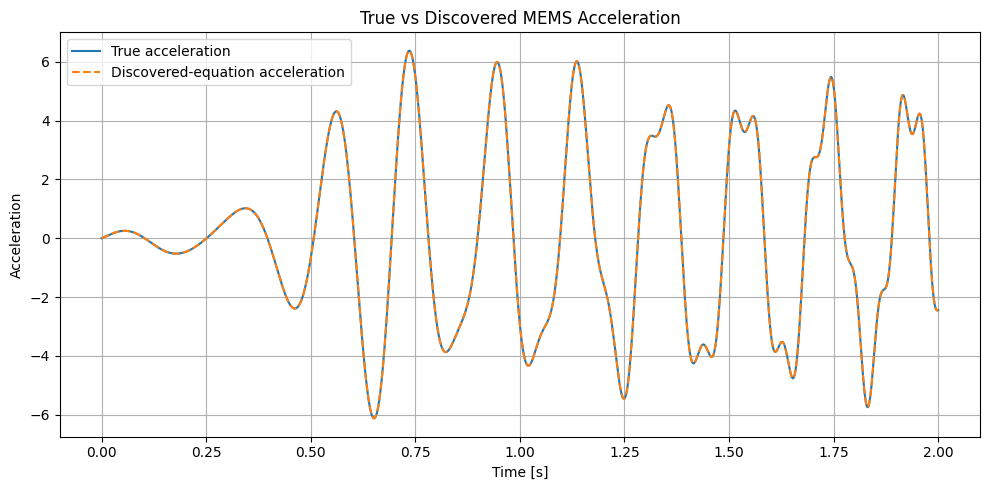

In [21]:
# PLOT TRUE AND DISCOVERED ACCELERATION

plt.figure(figsize=(10, 5))

plt.plot(
    time_values,
    acceleration,
    label="True acceleration",
)

plt.plot(
    time_values,
    discovered_acceleration,
    linestyle="--",
    label="Discovered-equation acceleration",
)

plt.xlabel("Time [s]")
plt.ylabel("Acceleration")

plt.title(
    "True vs Discovered MEMS Acceleration"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [24]:
# STUDY SINDY THRESHOLD SENSITIVITY

# Test several sparsity thresholds.
#
# Small thresholds may keep unnecessary terms.
# Large thresholds may remove physically meaningful terms.
sindy_thresholds = [
    0.001,
    0.01,
    0.05,
    0.1,
    0.5,
    1.0,
    2.0,
]


threshold_sensitivity_results = []


for threshold_value in sindy_thresholds:

    # Perform sparse regression.
    coefficients_normalized, active_mask = (
        sequential_threshold_least_squares(
            normalized_library=normalized_candidate_library,
            target=acceleration,
            threshold=threshold_value,
            max_iterations=20,
        )
    )


    # Convert back to physical coefficients.
    coefficients_physical = (
        convert_to_physical_coefficients(
            normalized_coefficients=coefficients_normalized,
            column_norms=candidate_norms,
        )
    )


    # Reconstruct acceleration.
    acceleration_prediction = (
        candidate_library
        @ coefficients_physical
    )


    # Calculate prediction RMSE.
    reconstruction_rmse = np.sqrt(
        np.mean(
            (
                acceleration
                - acceleration_prediction
            ) ** 2
        )
    )


    # Count how many candidate terms remain active.
    number_of_active_terms = np.sum(
        active_mask
    )


    # Store the active-term names.
    active_term_names = [
        candidate_names[index]
        for index in range(len(candidate_names))
        if active_mask[index]
    ]


    threshold_sensitivity_results.append(
        {
            "threshold": threshold_value,
            "number_of_active_terms": number_of_active_terms,
            "active_terms": ", ".join(active_term_names),
            "reconstruction_rmse": reconstruction_rmse,
        }
    )


threshold_sensitivity_table = pd.DataFrame(
    threshold_sensitivity_results
)


threshold_sensitivity_table

,threshold,number_of_active_terms,active_terms,reconstruction_rmse
0,0.001,3,"x, x_dot, F",3.697912e-14
1,0.010,3,"x, x_dot, F",3.697912e-14
2,0.050,3,"x, x_dot, F",3.697912e-14
3,0.100,3,"x, x_dot, F",3.697912e-14
4,0.500,3,"x, x_dot, F",3.697912e-14
5,1.000,3,"x, x_dot, F",3.697912e-14
6,2.000,2,"x, F",7.606229e-03


### Threshold Sensitivity

The sparse equation-discovery procedure was evaluated over several STLSQ threshold values.

For thresholds between

$$
0.001
$$

and

$$
1.0,
$$

the algorithm consistently selected the same three terms,

$$
x,\qquad \dot{x},\qquad F,
$$

and the acceleration-reconstruction RMSE remained approximately

$$
3.70\times10^{-14}.
$$

This indicates that the discovered governing equation is stable over a broad range of sparsity thresholds.

At a threshold of

$$
2.0,
$$

the damping term $\dot{x}$ was removed. The model then contained only

$$
x
$$

and

$$
F,
$$

and the reconstruction RMSE increased to approximately

$$
7.61\times10^{-3}.
$$

This shows that an excessively large sparsity threshold can remove physically meaningful terms. The originally selected threshold of $0.1$ therefore lies comfortably within a stable region.

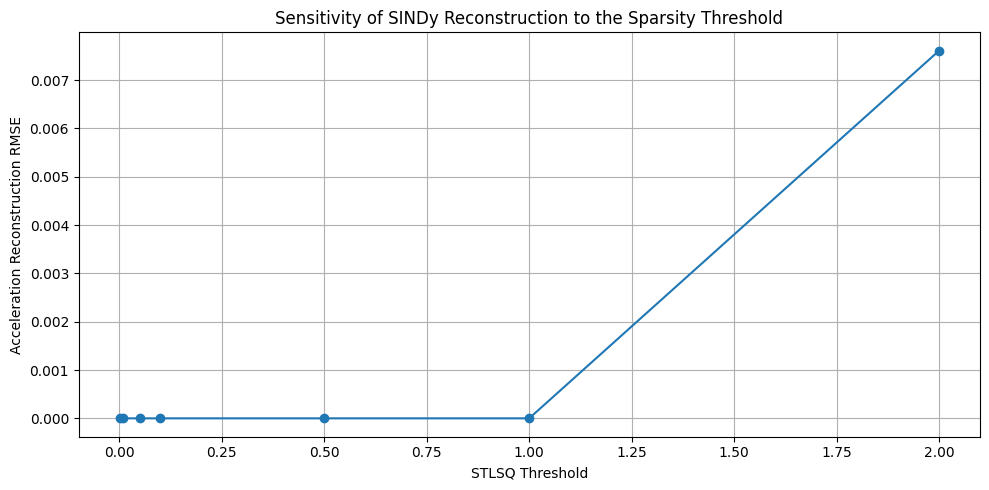

In [25]:
# PLOT SINDY THRESHOLD SENSITIVITY

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_sensitivity_table["threshold"],
    threshold_sensitivity_table["reconstruction_rmse"],
    marker="o",
)

plt.xlabel("STLSQ Threshold")
plt.ylabel("Acceleration Reconstruction RMSE")

plt.title(
    "Sensitivity of SINDy Reconstruction "
    "to the Sparsity Threshold"
)

plt.grid(True)
plt.tight_layout()

plt.show()

In [28]:
# TEST SINDY WITH NOISY ACCELERATION

# Create a reproducible random-number generator.
sindy_noise_rng = np.random.default_rng(
    seed=9512
)


# Define the acceleration-noise standard deviation.
sindy_noise_standard_deviation = 0.05


# Generate Gaussian measurement noise.
sindy_acceleration_noise = sindy_noise_rng.normal(
    loc=0.0,
    scale=sindy_noise_standard_deviation,
    size=acceleration.shape,
)


# Create the noisy acceleration measurement.
noisy_acceleration_sindy = (
    acceleration
    + sindy_acceleration_noise
)


# Apply STLSQ using the same normalized candidate library
# and the same threshold used for the deterministic case.
noisy_sparse_normalized_coefficients, noisy_active_terms = (
    sequential_threshold_least_squares(
        normalized_library=normalized_candidate_library,
        target=noisy_acceleration_sindy,
        threshold=sindy_threshold,
        max_iterations=20,
    )
)


# Convert the discovered coefficients back to the
# original physical feature scale.
noisy_sparse_physical_coefficients = (
    convert_to_physical_coefficients(
        normalized_coefficients=noisy_sparse_normalized_coefficients,
        column_norms=candidate_norms,
    )
)


# Collect the noisy equation-discovery result.
noisy_sparse_coefficient_table = pd.DataFrame(
    {
        "candidate_term": candidate_names,
        "active": noisy_active_terms,
        "physical_coefficient": noisy_sparse_physical_coefficients,
    }
)


noisy_sparse_coefficient_table

,candidate_term,active,physical_coefficient
0,1,False,0.000000
1,x,True,-1000.433111
2,x_dot,True,-0.081423
3,F,True,0.999617
4,x^2,False,0.000000
5,x*x_dot,False,0.000000
6,x_dot^2,False,0.000000
7,x^3,True,15156.866624


## SINDy under Measurement Noise

Gaussian noise with a standard deviation of

$$
\sigma = 0.05
$$

was added to the acceleration signal and the sparse equation-discovery procedure was repeated.

The physically expected terms remained active:

$$
x,\qquad \dot{x},\qquad F.
$$

Their recovered coefficients remained close to the deterministic values:

$$
x:\ -1000.43,
$$

$$
\dot{x}:\ -0.0814,
$$

and

$$
F:\ 0.9996.
$$

However, the cubic displacement term

$$
x^3
$$

was also selected.

Because the displacement amplitude is small, the numerical magnitude of $x^3$ is extremely small. Therefore, a large coefficient on this term does not necessarily imply a physically dominant cubic nonlinearity.

The activation of the extra nonlinear term indicates that measurement noise can cause sparse equation-discovery methods to retain spurious terms that partially fit the noisy observations. This motivates examining the actual contribution of each selected term rather than interpreting coefficient magnitude alone.

In [31]:
# ANALYSE THE CONTRIBUTION OF EACH ACTIVE SINDY TERM

term_contribution_results = []


for index, term_name in enumerate(candidate_names):

    if noisy_active_terms[index]:

        # Contribution of this term to the predicted acceleration.
        term_contribution = (
            candidate_library[:, index]
            * noisy_sparse_physical_coefficients[index]
        )


        # RMS magnitude gives a useful measure of how strongly
        # the term contributes across the whole time series.
        contribution_rms = np.sqrt(
            np.mean(
                term_contribution ** 2
            )
        )


        contribution_max_absolute = np.max(
            np.abs(
                term_contribution
            )
        )


        term_contribution_results.append(
            {
                "candidate_term": term_name,
                "physical_coefficient": (
                    noisy_sparse_physical_coefficients[index]
                ),
                "contribution_rms": contribution_rms,
                "contribution_max_absolute": (
                    contribution_max_absolute
                ),
            }
        )


term_contribution_table = pd.DataFrame(
    term_contribution_results
)


term_contribution_table

,candidate_term,physical_coefficient,contribution_rms,contribution_max_absolute
0,x,-1000.433111,2.994677,5.461567
1,x_dot,-0.081423,0.007769,0.015324
2,F,0.999617,0.703187,0.999617
3,x^3,15156.866624,0.000818,0.002466


### Contribution of the Selected Terms

The noisy SINDy model selected the physically expected terms together with an additional cubic displacement term.

Although the recovered coefficient of the cubic term was numerically large,

$$
15156.87,
$$

its actual contribution to the predicted acceleration was very small.

The RMS contributions were approximately

$$
2.995
$$

for the linear displacement term,

$$
0.703
$$

for the excitation term,

$$
0.00777
$$

for the damping-related velocity term, and only

$$
0.000818
$$

for the cubic displacement term.

The maximum absolute contribution of the cubic term was also only approximately

$$
0.00247.
$$

Therefore, the additional $x^3$ term does not represent a dominant physical nonlinearity in this experiment. Instead, it behaves as a very small noise-fitting term introduced by the sparse regression procedure.

This demonstrates that equation-discovery results should be interpreted using both the recovered coefficients and the actual dynamical contribution of each term.

In [32]:
# EVALUATE THE NOISY SINDY MODEL

# Reconstruct acceleration using the noisy sparse SINDy model.
noisy_sindy_acceleration = (
    candidate_library
    @ noisy_sparse_physical_coefficients
)



# ERROR RELATIVE TO THE NOISY MEASURED ACCELERATION
noisy_target_error = (
    noisy_acceleration_sindy
    - noisy_sindy_acceleration
)

noisy_target_rmse = np.sqrt(
    np.mean(
        noisy_target_error ** 2
    )
)

noisy_target_mae = np.mean(
    np.abs(
        noisy_target_error
    )
)



# ERROR RELATIVE TO THE CLEAN TRUE ACCELERATION
clean_target_error = (
    acceleration
    - noisy_sindy_acceleration
)

clean_target_rmse = np.sqrt(
    np.mean(
        clean_target_error ** 2
    )
)

clean_target_mae = np.mean(
    np.abs(
        clean_target_error
    )
)


print(
    f"RMSE relative to noisy acceleration: "
    f"{noisy_target_rmse:.6f}"
)

print(
    f"MAE relative to noisy acceleration:  "
    f"{noisy_target_mae:.6f}"
)

print()

print(
    f"RMSE relative to clean acceleration: "
    f"{clean_target_rmse:.6f}"
)

print(
    f"MAE relative to clean acceleration:  "
    f"{clean_target_mae:.6f}"
)

RMSE relative to noisy acceleration: 0.049843
MAE relative to noisy acceleration:  0.039803

RMSE relative to clean acceleration: 0.000715
MAE relative to clean acceleration:  0.000621


### Noisy SINDy Reconstruction Accuracy

The noisy SINDy model was evaluated against both the noisy acceleration measurements and the underlying clean acceleration signal.

Relative to the noisy acceleration, the reconstruction errors were

$$
\mathrm{RMSE}=0.049843
$$

and

$$
\mathrm{MAE}=0.039803.
$$

These values are consistent with the imposed acceleration-noise level of

$$
\sigma=0.05.
$$

Relative to the clean acceleration signal, however, the errors were much smaller:

$$
\mathrm{RMSE}=0.000715
$$

and

$$
\mathrm{MAE}=0.000621.
$$

This indicates that the sparse discovered model remains very close to the underlying deterministic dynamics, even though it cannot reproduce the random measurement noise.

The result also illustrates an important distinction between fitting noisy measurements and recovering the underlying physical system.

In [33]:
# SAVE MAIN SINDY RESULTS

# Create the equation-discovery results directory.
equation_discovery_results_directory = results_path(
    "equation_discovery"
)

ensure_directory(
    equation_discovery_results_directory
)


# Save the deterministic sparse coefficient table.
deterministic_sindy_path = (
    equation_discovery_results_directory
    / "deterministic_sindy_coefficients.csv"
)

sparse_coefficient_table.to_csv(
    deterministic_sindy_path,
    index=False,
)


# Save the threshold-sensitivity table.
threshold_sensitivity_path = (
    equation_discovery_results_directory
    / "sindy_threshold_sensitivity.csv"
)

threshold_sensitivity_table.to_csv(
    threshold_sensitivity_path,
    index=False,
)


# Save the noisy SINDy coefficient table.
noisy_sindy_path = (
    equation_discovery_results_directory
    / "noisy_sindy_coefficients.csv"
)

noisy_sparse_coefficient_table.to_csv(
    noisy_sindy_path,
    index=False,
)


# Save the noisy term-contribution analysis.
term_contribution_path = (
    equation_discovery_results_directory
    / "noisy_sindy_term_contributions.csv"
)

term_contribution_table.to_csv(
    term_contribution_path,
    index=False,
)


print("Deterministic SINDy coefficients saved to:")
print(deterministic_sindy_path)

print()

print("Threshold sensitivity saved to:")
print(threshold_sensitivity_path)

print()

print("Noisy SINDy coefficients saved to:")
print(noisy_sindy_path)

print()

print("Noisy term contributions saved to:")
print(term_contribution_path)

Deterministic SINDy coefficients saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\equation_discovery\deterministic_sindy_coefficients.csv

Threshold sensitivity saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\equation_discovery\sindy_threshold_sensitivity.csv

Noisy SINDy coefficients saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\equation_discovery\noisy_sindy_coefficients.csv

Noisy term contributions saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\equation_discovery\noisy_sindy_term_contributions.csv


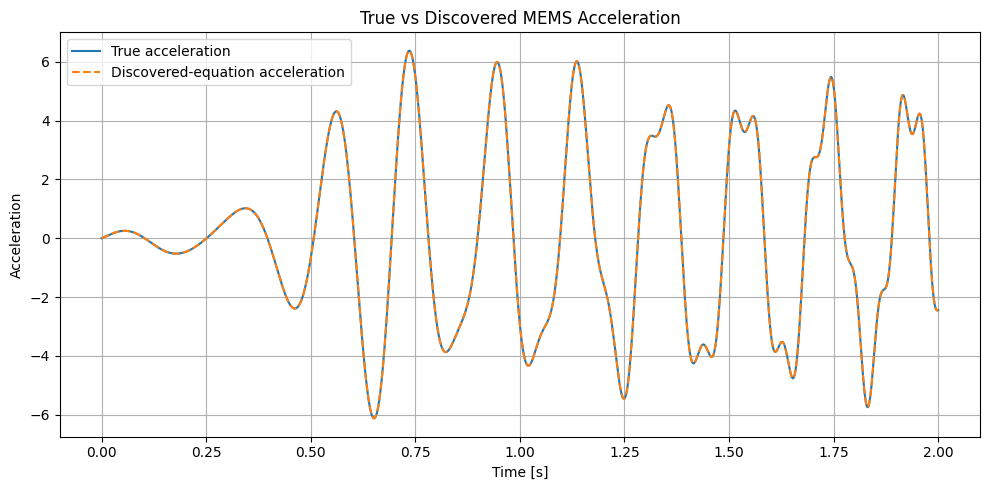

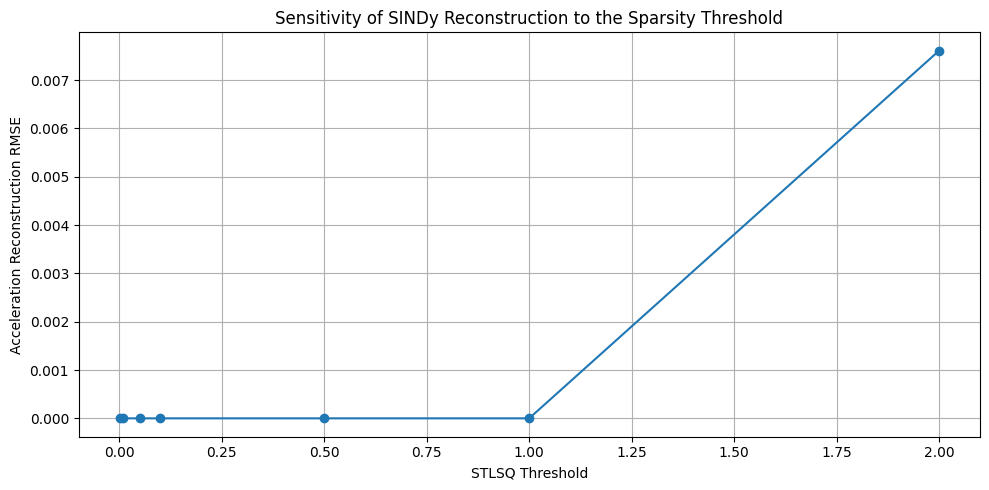

Acceleration-reconstruction figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\equation_discovery\deterministic_sindy_acceleration_reconstruction.png

Threshold-sensitivity figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\equation_discovery\sindy_threshold_sensitivity.png


In [34]:
# SAVE MAIN SINDY FIGURES

equation_discovery_figure_directory = figures_path(
    "equation_discovery"
)

ensure_directory(
    equation_discovery_figure_directory
)



# SAVE TRUE VS DISCOVERED ACCELERATION FIGURE
plt.figure(figsize=(10, 5))

plt.plot(
    time_values,
    acceleration,
    label="True acceleration",
)

plt.plot(
    time_values,
    discovered_acceleration,
    linestyle="--",
    label="Discovered-equation acceleration",
)

plt.xlabel("Time [s]")
plt.ylabel("Acceleration")
plt.title(
    "True vs Discovered MEMS Acceleration"
)

plt.legend()
plt.grid(True)
plt.tight_layout()


discovered_acceleration_figure_path = (
    equation_discovery_figure_directory
    / "deterministic_sindy_acceleration_reconstruction.png"
)

plt.savefig(
    discovered_acceleration_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()



# SAVE THRESHOLD-SENSITIVITY FIGURE
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_sensitivity_table["threshold"],
    threshold_sensitivity_table["reconstruction_rmse"],
    marker="o",
)

plt.xlabel("STLSQ Threshold")
plt.ylabel("Acceleration Reconstruction RMSE")

plt.title(
    "Sensitivity of SINDy Reconstruction "
    "to the Sparsity Threshold"
)

plt.grid(True)
plt.tight_layout()


threshold_sensitivity_figure_path = (
    equation_discovery_figure_directory
    / "sindy_threshold_sensitivity.png"
)

plt.savefig(
    threshold_sensitivity_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("Acceleration-reconstruction figure saved to:")
print(discovered_acceleration_figure_path)

print()

print("Threshold-sensitivity figure saved to:")
print(threshold_sensitivity_figure_path)

In [35]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 05

notebook_05_outputs = {
    "deterministic_sindy_results": deterministic_sindy_path,
    "threshold_sensitivity_results": threshold_sensitivity_path,
    "noisy_sindy_results": noisy_sindy_path,
    "term_contribution_results": term_contribution_path,
    "acceleration_reconstruction_figure": discovered_acceleration_figure_path,
    "threshold_sensitivity_figure": threshold_sensitivity_figure_path,
}


for output_name, output_path in notebook_05_outputs.items():

    print(
        f"{output_name:34s} "
        f"{output_path.exists()}"
    )

deterministic_sindy_results        True
threshold_sensitivity_results      True
noisy_sindy_results                True
term_contribution_results          True
acceleration_reconstruction_figure True
threshold_sensitivity_figure       True


# Notebook 05 Summary

This notebook applied sparse equation discovery to the deterministic MEMS dynamical system.

A candidate-function library containing linear and nonlinear terms was constructed and normalized before applying Sequentially Thresholded Least Squares.

For the deterministic baseline, SINDy retained only

$$
x,\qquad \dot{x},\qquad F,
$$

and recovered the governing equation

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F(t).
$$

This matches the known physical model exactly for the unit-mass baseline system.

The acceleration reconstructed from the discovered equation had an RMSE of approximately

$$
3.70\times10^{-14},
$$

indicating agreement with the deterministic simulation to numerical precision.

A threshold-sensitivity analysis showed that the same governing-equation structure was recovered consistently for STLSQ thresholds between

$$
0.001
$$

and

$$
1.0.
$$

At a threshold of $2.0$, the damping-related velocity term was removed and the reconstruction error increased, demonstrating the effect of excessive sparsification.

Measurement noise was then added to the acceleration signal. The noisy SINDy model retained the physically expected terms but also selected a small cubic displacement contribution.

Although the recovered coefficient of the cubic term was numerically large, its RMS contribution to the acceleration was only approximately

$$
0.000818,
$$

showing that coefficient magnitude alone is not sufficient to determine physical importance.

The noisy SINDy model remained very close to the underlying clean dynamics, with a clean-signal reconstruction RMSE of approximately

$$
0.000715.
$$

These results demonstrate that sparse equation discovery can recover the governing structure and coefficients of the MEMS system from data, while also showing how measurement noise can introduce small spurious terms that require careful physical interpretation.